# Scaling Laws for Neural Language Models (Scaling Laws)

**Paper:** [arXiv:2001.08361](https://arxiv.org/abs/2001.08361)
**Authors:** Jared Kaplan, Sam McCandlish, Tom Henighan, Tom B. Brown, Benjamin Chess, Rewon Child, Scott Gray, Alec Radford, Jeffrey Wu, Dario Amodei (2020; arXiv preprint)

This notebook trains 6 tiny decoder-only Transformers of different sizes on character-level WikiText-2,
then fits the power law $L(N) = (N_c/N)^{\alpha_N}$ to the resulting validation losses.
It also varies dataset size to reproduce the overfitting relationship $L(N,D)$ from the paper.

**Simplifications vs the paper** (same list as README and CODE_ARCHITECTURE):
- Character-level WikiText-2 (~10.8M characters, 283-char vocab) instead of WebText2 (22.9B BPE tokens, 50,257 vocab)
- 6 models from ~25K to ~793K non-embedding parameters instead of 768 to 1.5 billion
- 2000 steps with Adam (lr 3e-3, cosine decay) instead of 250K steps with 512×1024-token batches
- Context length 128 characters instead of 1024 tokens
- Pure PyTorch; no FP16, no distributed training

<!-- Rules: keep real line breaks in every markdown cell; no auto-injected Kaggle validator cell;
silence download/progress bars; keep the notebook well under 1 MB; every claim must be visible in a saved output. -->

## 1. Setup & Imports

In [1]:
import contextlib
import io
import math
import os
import random
import time
import urllib.request

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# --- Hyperparameters (the ONLY place these values live; docs copy them from here) ---
SEQ_LEN = 128
BATCH_SIZE = 64
STEPS = 2000          # training steps per model
LR = 3e-3
WARMUP_STEPS = 200

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')

Device: cuda


## 2. Data

We use WikiText-2 at character level (~10.8M characters, 283-character vocabulary). This is a small,
well-known language modelling corpus. We download it quietly to /tmp and encode it as integer character IDs.
For the $L(N,D)$ experiment we train on fractions of the full dataset to simulate finite data.

In [2]:
DATA_DIR = '/tmp/wikitext2'
os.makedirs(DATA_DIR, exist_ok=True)

train_url = 'https://raw.githubusercontent.com/pytorch/examples/main/word_language_model/data/wikitext-2/train.txt'
valid_url = 'https://raw.githubusercontent.com/pytorch/examples/main/word_language_model/data/wikitext-2/valid.txt'

with contextlib.redirect_stderr(io.StringIO()), contextlib.redirect_stdout(io.StringIO()):
    for name, url in [('train.txt', train_url), ('valid.txt', valid_url)]:
        path = os.path.join(DATA_DIR, name)
        if not os.path.exists(path):
            urllib.request.urlretrieve(url, path)

with open(os.path.join(DATA_DIR, 'train.txt'), 'r') as f:
    train_text = f.read()
with open(os.path.join(DATA_DIR, 'valid.txt'), 'r') as f:
    valid_text = f.read()

chars = sorted(set(train_text))
VOCAB_SIZE = len(chars)
char_to_idx = {c: i for i, c in enumerate(chars)}
idx_to_char = {i: c for i, c in enumerate(chars)}

train_data = torch.tensor([char_to_idx[c] for c in train_text], dtype=torch.long)
valid_data = torch.tensor([char_to_idx[c] for c in valid_text], dtype=torch.long)

print(f'Vocab size: {VOCAB_SIZE}')
print(f'Train chars: {len(train_data):,}')
print(f'Valid chars: {len(valid_data):,}')
print(f'Sample text: {train_text[:120]!r}')

Vocab size: 283
Train chars: 10,780,437
Valid chars: 1,120,192
Sample text: ' \n = Valkyria Chronicles III = \n \n Senjō no Valkyria 3 : <unk> Chronicles ( Japanese : 戦場のヴァルキュリア3 , lit . Valkyria of t'


In [3]:
def get_batch(data, batch_size, seq_len, device):
    """Sample a random batch of sequences from the data tensor."""
    ix = torch.randint(max(1, len(data) - seq_len - 1), (batch_size,))
    x = torch.stack([data[i:i+seq_len] for i in ix])
    y = torch.stack([data[i+1:i+1+seq_len] for i in ix])
    return x.to(device), y.to(device)

xb, yb = get_batch(train_data, 4, SEQ_LEN, DEVICE)
print(f'Batch shape: {xb.shape}  (batch_size, seq_len)')
print(f'Target shape: {yb.shape}')

Batch shape: torch.Size([4, 128])  (batch_size, seq_len)
Target shape: torch.Size([4, 128])


## 3. Model

A minimal decoder-only Transformer with causal self-attention, following the architecture
in the paper (Section 2.1). The parameter count $N$ excludes embedding parameters, matching
the paper's convention: $N \approx 12 \, n_{\text{layer}} \, d_{\text{model}}^2$.
We train 6 models of increasing size by scaling $d_{\text{model}}$ and $n_{\text{layer}}$.

In [4]:
class TinyTransformer(nn.Module):
    """Decoder-only Transformer with causal self-attention."""
    def __init__(self, vocab_size, d_model, n_layers, n_heads, d_ff, seq_len):
        super().__init__()
        self.token_emb = nn.Embedding(vocab_size, d_model)
        self.pos_emb = nn.Embedding(seq_len, d_model)
        self.layers = nn.ModuleList([
            nn.TransformerEncoderLayer(
                d_model=d_model, nhead=n_heads, dim_feedforward=d_ff,
                dropout=0.0, activation='gelu', batch_first=True, norm_first=True
            ) for _ in range(n_layers)
        ])
        self.ln_f = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, vocab_size, bias=False)
        self.head.weight = self.token_emb.weight  # weight tying

    def forward(self, idx):
        B, T = idx.shape
        pos = torch.arange(T, device=idx.device).unsqueeze(0)
        x = self.token_emb(idx) + self.pos_emb(pos)
        mask = torch.triu(torch.ones(T, T, device=idx.device, dtype=torch.bool), diagonal=1)
        for layer in self.layers:
            x = layer(x, src_mask=mask)
        x = self.ln_f(x)
        return self.head(x)

def count_non_embedding_params(model):
    """Count parameters excluding token and positional embeddings."""
    total = sum(p.numel() for p in model.parameters())
    emb = model.token_emb.weight.numel() + model.pos_emb.weight.numel()
    return total - emb

# (d_model, n_layers, n_heads, d_ff) — 6 configs spanning ~30x in parameters
CONFIGS = [
    (32,  2, 4, 128),
    (48,  2, 4, 192),
    (64,  3, 4, 256),
    (80,  3, 4, 320),
    (96,  4, 4, 384),
    (128, 4, 4, 512),
]

print('Model configurations:')
print(f'{"d_model":>8} {"layers":>6} {"heads":>6} {"d_ff":>6} {"N (non-emb)":>14}')
for d, l, h, ff in CONFIGS:
    m = TinyTransformer(VOCAB_SIZE, d, l, h, ff, SEQ_LEN)
    n = count_non_embedding_params(m)
    del m
    print(f'{d:>8} {l:>6} {h:>6} {ff:>6} {n:>14,}')

Model configurations:
 d_model layers  heads   d_ff    N (non-emb)
      32      2      4    128         25,472
      48      2      4    192         56,640
      64      3      4    256        150,080
      80      3      4    320        233,680
      96      4      4    384        447,552
     128      4      4    512        793,344


## 4. Loss Function

Standard cross-entropy loss averaged over all tokens in the context, matching the paper's
metric $L$ — the cross-entropy loss in nats (Section 2).

In [5]:
def compute_loss(model, x, y):
    logits = model(x)
    return F.cross_entropy(logits.view(-1, VOCAB_SIZE), y.view(-1))

def evaluate(model, data, n_batches=30):
    """Evaluate validation loss on n_batches of random sequences."""
    model.eval()
    losses = []
    with torch.no_grad():
        for _ in range(n_batches):
            x, y = get_batch(data, BATCH_SIZE, SEQ_LEN, DEVICE)
            losses.append(compute_loss(model, x, y).item())
    model.train()
    return np.mean(losses)

def get_lr(step, total_steps, warmup, max_lr):
    """Linear warmup then cosine decay to zero (paper Section 2.1)."""
    if step < warmup:
        return max_lr * step / warmup
    progress = (step - warmup) / max(1, total_steps - warmup)
    return max_lr * 0.5 * (1 + math.cos(math.pi * progress))

## 5. Training Loop

Each model is trained for a fixed number of steps with the Adam optimizer and a
warmup + cosine decay schedule (paper Section 2.1). We log validation loss every 500 steps.
The paper trained for 250K steps at batch size 512×1024 tokens; we use 2000 steps at
batch size 64×128 characters to keep the experiment under a few minutes per model on GPU.

In [6]:
def train_model(config, steps=STEPS, data_limit=None):
    """Train a TinyTransformer; return (non_emb_params, final_val_loss, val_history)."""
    d_model, n_layers, n_heads, d_ff = config
    model = TinyTransformer(VOCAB_SIZE, d_model, n_layers, n_heads, d_ff, SEQ_LEN).to(DEVICE)
    n_params = count_non_embedding_params(model)
    optimizer = optim.Adam(model.parameters(), lr=LR)

    train_slice = train_data if data_limit is None else train_data[:data_limit]

    val_history = []
    start = time.time()
    model.train()
    for step in range(1, steps + 1):
        lr = get_lr(step, steps, WARMUP_STEPS, LR)
        for pg in optimizer.param_groups:
            pg['lr'] = lr
        x, y = get_batch(train_slice, BATCH_SIZE, SEQ_LEN, DEVICE)
        loss = compute_loss(model, x, y)
        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()

        if step % 500 == 0 or step == steps:
            val_loss = evaluate(model, valid_data, n_batches=30)
            val_history.append((step, val_loss))
            elapsed = time.time() - start
            print(f'  Step {step:>5d}/{steps}  train_loss {loss.item():.4f}  val_loss {val_loss:.4f}  lr {lr:.2e}  [{elapsed:.0f}s]')

    final_val = evaluate(model, valid_data, n_batches=50)
    total_time = time.time() - start
    print(f'  Done: N={n_params:,}  final_val_loss={final_val:.4f}  time={total_time:.0f}s')
    del model
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()
    return n_params, final_val, val_history

## 6. Experiment 1: Scaling with Model Size $N$

In [7]:
print('=' * 70)
print('Experiment 1: Train 6 models of increasing size, fit L(N) = (Nc/N)^aN')
print('=' * 70)

results_N = []
for i, cfg in enumerate(CONFIGS):
    print(f'\n--- Model {i+1}/{len(CONFIGS)}: d_model={cfg[0]}, layers={cfg[1]} ---')
    n, vloss, vhist = train_model(cfg)
    results_N.append((n, vloss, vhist))

print('\n' + '=' * 70)
print('Summary: N vs Validation Loss')
print('=' * 70)
print(f'{"N (non-emb)":>14} {"Val Loss":>10} {"Perplexity":>12}')
for n, vloss, _ in results_N:
    print(f'{n:>14,} {vloss:>10.4f} {math.exp(vloss):>12.2f}')

Experiment 1: Train 6 models of increasing size, fit L(N) = (Nc/N)^aN

--- Model 1/6: d_model=32, layers=2 ---


  Step   500/2000  train_loss 2.4521  val_loss 2.3636  lr 2.80e-03  [5s]


  Step  1000/2000  train_loss 2.3406  val_loss 2.2806  lr 1.76e-03  [9s]


  Step  1500/2000  train_loss 2.3302  val_loss 2.2417  lr 5.36e-04  [13s]


  Step  2000/2000  train_loss 2.3203  val_loss 2.2260  lr 0.00e+00  [17s]
  Done: N=25,472  final_val_loss=2.2256  time=17s

--- Model 2/6: d_model=48, layers=2 ---


...

  Step   500/2000  train_loss 2.0425  val_loss 1.9812  lr 2.80e-03  [16s]


  Step  1000/2000  train_loss 1.6370  val_loss 1.5663  lr 1.76e-03  [32s]


  Step  1500/2000  train_loss 1.5104  val_loss 1.4325  lr 5.36e-04  [49s]


  Step  2000/2000  train_loss 1.4839  val_loss 1.3994  lr 0.00e+00  [65s]


  Done: N=793,344  final_val_loss=1.3976  time=66s

Summary: N vs Validation Loss
   N (non-emb)   Val Loss   Perplexity
        25,472     2.2256         9.26
        56,640     1.9621         7.11
       150,080     1.7686         5.86
       233,680     1.6158         5.03
       447,552     1.4785         4.39
       793,344     1.3976         4.05


## 7. Fitting the Power Law

The paper's key result (Equation 1.1): $L(N) = (N_c / N)^{\alpha_N}$ with
$\alpha_N \approx 0.076$ and $N_c \approx 8.8 \times 10^{13}$.

We fit $\log L = \alpha_N \log N_c - \alpha_N \log N$ (linear fit in log-log space)
to our 6 data points. Our fitted $\alpha_N$ and $N_c$ will differ from the paper's values
because we train far smaller models on a tiny character-level dataset — but the power-law
*shape* should still emerge.

In [8]:
Ns = np.array([r[0] for r in results_N], dtype=np.float64)
Ls = np.array([r[1] for r in results_N], dtype=np.float64)

# Linear fit in log-log space: log(L) = a * log(N) + b, a = -alpha_N, b = alpha_N * log(Nc)
log_N = np.log(Ns)
log_L = np.log(Ls)
coeffs = np.polyfit(log_N, log_L, 1)
alpha_N_fit = -coeffs[0]
Nc_fit = np.exp(coeffs[1] / alpha_N_fit)

log_L_pred = np.polyval(coeffs, log_N)
ss_res = np.sum((log_L - log_L_pred)**2)
ss_tot = np.sum((log_L - np.mean(log_L))**2)
r_squared = 1 - ss_res / ss_tot

print(f'Paper values:     alpha_N = 0.076,  Nc = 8.8e13')
print(f'Our fit:           alpha_N = {alpha_N_fit:.4f},  Nc = {Nc_fit:.2e}')
print(f'  (Values differ because our models are ~10^6x smaller and use char-level data)')
print(f'  R-squared = {r_squared:.6f}')

L_pred = (Nc_fit / Ns) ** alpha_N_fit
print(f'\n{"N":>12} {"L_actual":>10} {"L_predicted":>12} {"error%":>8}')
for n, la, lp in zip(Ns, Ls, L_pred):
    print(f'{n:>12,.0f} {la:>10.4f} {lp:>12.4f} {100*(la-lp)/la:>7.1f}%')

Paper values:     alpha_N = 0.076,  Nc = 8.8e13
Our fit:           alpha_N = 0.1367,  Nc = 8.52e+06
  (Values differ because our models are ~10^6x smaller and use char-level data)
  R-squared = 0.994399

           N   L_actual  L_predicted   error%
      25,472     2.2256       2.2129     0.6%
      56,640     1.9621       1.9840    -1.1%
     150,080     1.7686       1.7366     1.8%
     233,680     1.6158       1.6347    -1.2%
     447,552     1.4785       1.4958    -1.2%
     793,344     1.3976       1.3832     1.0%


## 8. Scaling Law Plots

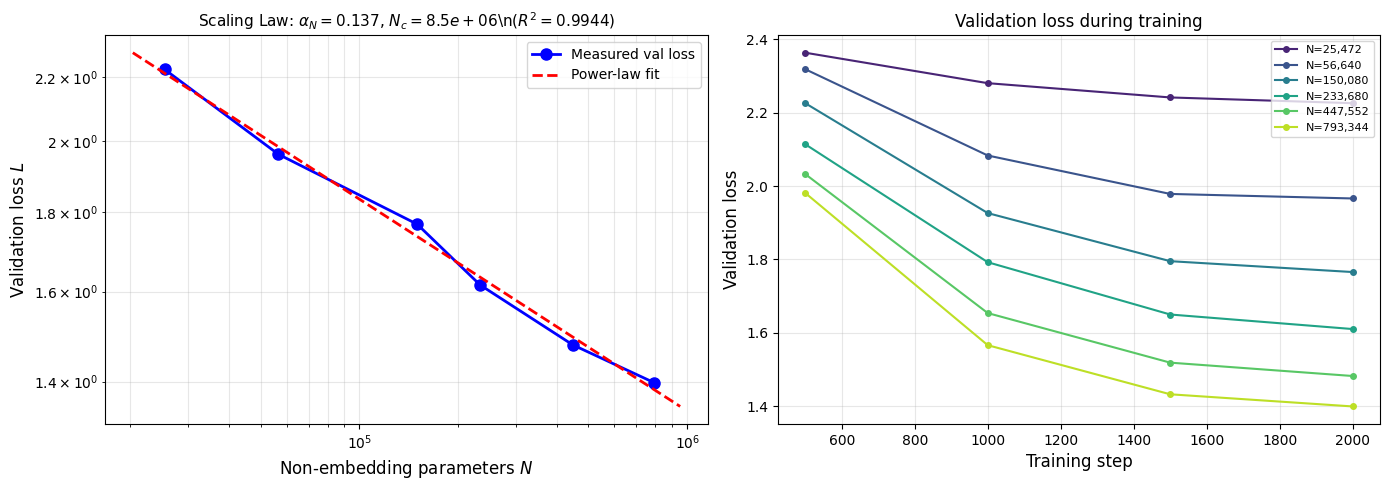

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
ax.loglog(Ns, Ls, 'bo-', markersize=8, linewidth=2, label='Measured val loss')
N_smooth = np.logspace(np.log10(Ns.min()*0.8), np.log10(Ns.max()*1.2), 100)
L_smooth = (Nc_fit / N_smooth) ** alpha_N_fit
ax.loglog(N_smooth, L_smooth, 'r--', linewidth=2, label=f'Power-law fit')
ax.set_xlabel('Non-embedding parameters $N$', fontsize=12)
ax.set_ylabel('Validation loss $L$', fontsize=12)
ax.set_title(f'Scaling Law: $\\alpha_N={alpha_N_fit:.3f}$, $N_c={Nc_fit:.1e}$\\n($R^2={r_squared:.4f}$)', fontsize=11)
ax.legend(fontsize=10)
ax.grid(True, which='both', alpha=0.3)

ax = axes[1]
colors = plt.cm.viridis(np.linspace(0.1, 0.9, len(results_N)))
for (n, vloss, vhist), color in zip(results_N, colors):
    steps_arr = [h[0] for h in vhist]
    vals_arr = [h[1] for h in vhist]
    ax.plot(steps_arr, vals_arr, '-o', color=color, markersize=4, label=f'N={n:,}')
ax.set_xlabel('Training step', fontsize=12)
ax.set_ylabel('Validation loss', fontsize=12)
ax.set_title('Validation loss during training', fontsize=12)
ax.legend(fontsize=8, loc='upper right')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 9. Experiment 2: Overfitting with Limited Data $L(N,D)$

The paper's Equation (1.5): $L(N,D) = \left[\left(\frac{N_c}{N}\right)^{\frac{\alpha_N}{\alpha_D}} + \frac{D_c}{D}\right]^{\alpha_D}$

When data $D$ is limited, larger models overfit more. We train the smallest and largest models
on decreasing fractions of the training data to show this overfitting effect.

In [10]:
print('=' * 70)
print('Experiment 2: Vary dataset size D for smallest and largest models')
print('=' * 70)

D_SIZES = [20000, 50000, 100000, 200000, len(train_data)]
D_LABELS = ['20K', '50K', '100K', '200K', 'Full']

small_cfg = CONFIGS[0]
large_cfg = CONFIGS[-1]

results_D = {'small': [], 'large': []}

for label, cfg, key in [('Small', small_cfg, 'small'), ('Large', large_cfg, 'large')]:
    print(f'\n--- {label} model (d_model={cfg[0]}, layers={cfg[1]}) ---')
    for d_size, d_label in zip(D_SIZES, D_LABELS):
        print(f'  D = {d_label} ({d_size:,} chars):')
        n, vloss, _ = train_model(cfg, steps=STEPS, data_limit=d_size)
        results_D[key].append((d_size, vloss))

print('\n' + '=' * 70)
print('L(N,D) Summary')
print('=' * 70)
print(f'{"D (chars)":>12} {"Small L":>10} {"Large L":>10} {"Overfit gap":>12}')
for (d, ls), (_, ll) in zip(results_D['small'], results_D['large']):
    print(f'{d:>12,} {ls:>10.4f} {ll:>10.4f} {ll-ls:>12.4f}')

Experiment 2: Vary dataset size D for smallest and largest models

--- Small model (d_model=32, layers=2) ---
  D = 20K (20,000 chars):


  Step   500/2000  train_loss 2.3135  val_loss 2.4972  lr 2.80e-03  [4s]


  Step  1000/2000  train_loss 2.0790  val_loss 2.4786  lr 1.76e-03  [8s]


  Step  1500/2000  train_loss 1.8115  val_loss 2.4294  lr 5.36e-04  [12s]


  Step  2000/2000  train_loss 1.7803  val_loss 2.4462  lr 0.00e+00  [16s]
  Done: N=25,472  final_val_loss=2.4625  time=16s


...

  Step   500/2000  train_loss 2.1357  val_loss 2.0270  lr 2.80e-03  [16s]


  Step  1000/2000  train_loss 1.7211  val_loss 1.6316  lr 1.76e-03  [33s]


  Step  1500/2000  train_loss 1.5841  val_loss 1.4753  lr 5.36e-04  [49s]


  Step  2000/2000  train_loss 1.5206  val_loss 1.4421  lr 0.00e+00  [66s]


  Done: N=793,344  final_val_loss=1.4410  time=66s

L(N,D) Summary
   D (chars)    Small L    Large L  Overfit gap
      20,000     2.4625     8.8694       6.4068
      50,000     2.2326     6.2265       3.9939
     100,000     2.2240     3.4144       1.1904
     200,000     2.2543     1.9084      -0.3459
  10,780,437     2.2190     1.4410      -0.7780


## 10. Overfitting Plot

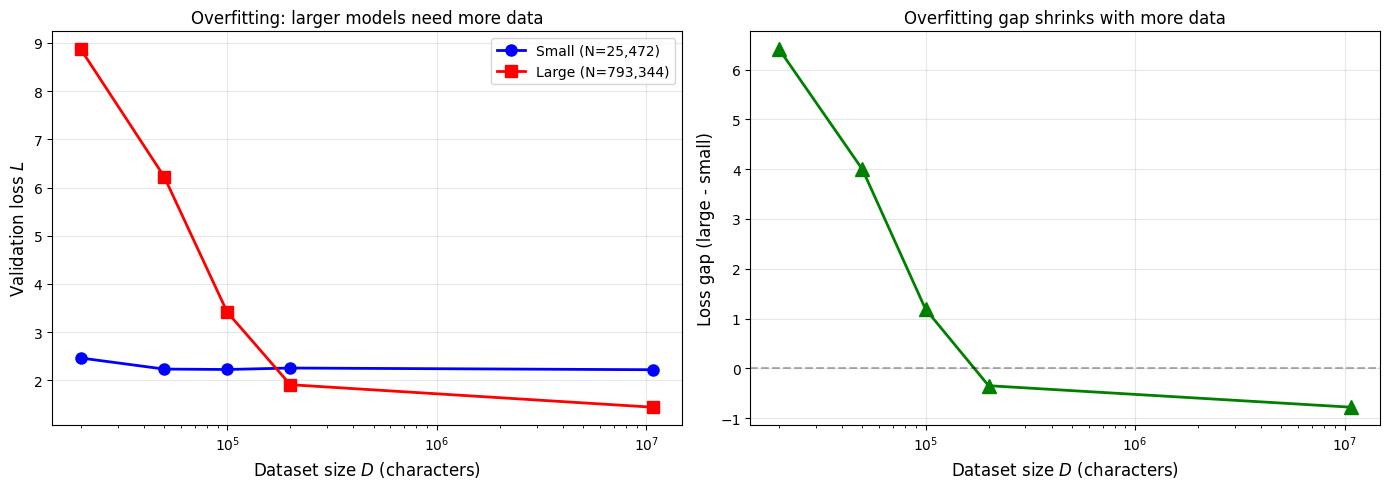

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
Ds = np.array([r[0] for r in results_D['small']], dtype=float)
Ls_small = np.array([r[1] for r in results_D['small']])
Ls_large = np.array([r[1] for r in results_D['large']])
ax.semilogx(Ds, Ls_small, 'bo-', markersize=8, linewidth=2, label=f'Small (N={results_N[0][0]:,})')
ax.semilogx(Ds, Ls_large, 'rs-', markersize=8, linewidth=2, label=f'Large (N={results_N[-1][0]:,})')
ax.set_xlabel('Dataset size $D$ (characters)', fontsize=12)
ax.set_ylabel('Validation loss $L$', fontsize=12)
ax.set_title('Overfitting: larger models need more data', fontsize=12)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)

ax = axes[1]
gap = Ls_large - Ls_small
ax.semilogx(Ds, gap, 'g^-', markersize=10, linewidth=2)
ax.set_xlabel('Dataset size $D$ (characters)', fontsize=12)
ax.set_ylabel('Loss gap (large - small)', fontsize=12)
ax.set_title('Overfitting gap shrinks with more data', fontsize=12)
ax.grid(True, alpha=0.3)
ax.axhline(y=0, color='k', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

## 11. Experiment 3: Compute Scaling $L(C)$

The paper's Equation (1.3): $L(C_{\min}) = (C_c^{\min}/C_{\min})^{\alpha_C^{\min}}$
with $\alpha_C^{\min} \approx 0.050$. We estimate compute as $C \approx 6 N B S$
(paper Section 2.1) for each model and fit the power law.

In [12]:
batch_tokens = BATCH_SIZE * SEQ_LEN

print('Compute estimates for each model:')
print(f'{"N":>12} {"Val Loss":>10} {"C (FLOPs)":>16} {"log10(C)":>10}')
Cs = []
for n, vloss, _ in results_N:
    C = 6 * n * batch_tokens * STEPS
    Cs.append(C)
    print(f'{n:>12,} {vloss:>10.4f} {C:>16.2e} {np.log10(C):>10.2f}')

Cs = np.array(Cs)
Ls_C = np.array([r[1] for r in results_N])

log_C = np.log(Cs)
log_LC = np.log(Ls_C)
coeffs_C = np.polyfit(log_C, log_LC, 1)
alpha_C_fit = -coeffs_C[0]
Cc_fit = np.exp(coeffs_C[1] / alpha_C_fit)

log_LC_pred = np.polyval(coeffs_C, log_C)
ss_res_C = np.sum((log_LC - log_LC_pred)**2)
ss_tot_C = np.sum((log_LC - np.mean(log_LC))**2)
r2_C = 1 - ss_res_C / ss_tot_C

print(f'\nCompute scaling fit: L(C) = (Cc/C)^alpha_C')
print(f'  alpha_C = {alpha_C_fit:.4f}  (paper: ~0.05)')
print(f'  Cc = {Cc_fit:.2e}')
print(f'  R-squared = {r2_C:.6f}')

Compute estimates for each model:
           N   Val Loss        C (FLOPs)   log10(C)
      25,472     2.2256         2.50e+12      12.40
      56,640     1.9621         5.57e+12      12.75
     150,080     1.7686         1.48e+13      13.17
     233,680     1.6158         2.30e+13      13.36
     447,552     1.4785         4.40e+13      13.64
     793,344     1.3976         7.80e+13      13.89

Compute scaling fit: L(C) = (Cc/C)^alpha_C
  alpha_C = 0.1367  (paper: ~0.05)
  Cc = 8.38e+14
  R-squared = 0.994399


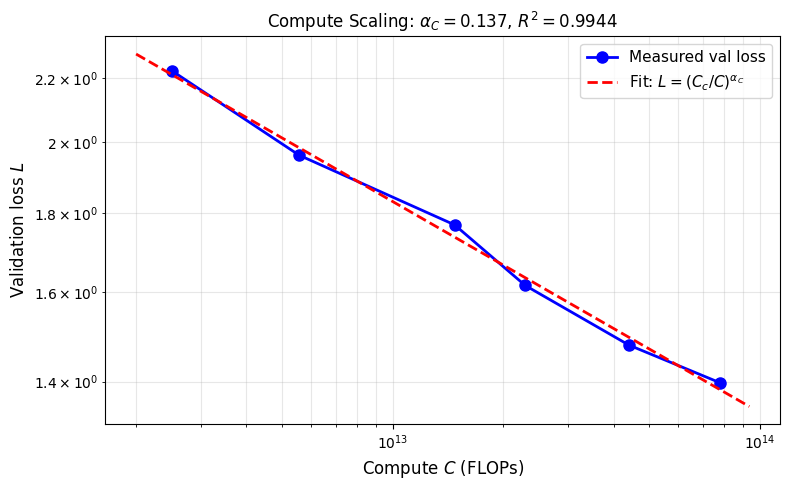

In [13]:
fig, ax = plt.subplots(1, 1, figsize=(8, 5))
ax.loglog(Cs, Ls_C, 'bo-', markersize=8, linewidth=2, label='Measured val loss')
C_smooth = np.logspace(np.log10(Cs.min()*0.8), np.log10(Cs.max()*1.2), 100)
L_C_smooth = (Cc_fit / C_smooth) ** alpha_C_fit
ax.loglog(C_smooth, L_C_smooth, 'r--', linewidth=2, label=r'Fit: $L=(C_c/C)^{\alpha_C}$')
ax.set_xlabel('Compute $C$ (FLOPs)', fontsize=12)
ax.set_ylabel('Validation loss $L$', fontsize=12)
ax.set_title(f'Compute Scaling: $\\alpha_C={alpha_C_fit:.3f}$, $R^2={r2_C:.4f}$', fontsize=12)
ax.legend(fontsize=11)
ax.grid(True, which='both', alpha=0.3)
plt.tight_layout()
plt.show()

## 12. Sample Efficiency

The paper observes that larger models are more sample-efficient: they reach the same loss
with fewer training steps (Figure 2). We overlay the training curves from Experiment 1
to check this trend in our tiny models.

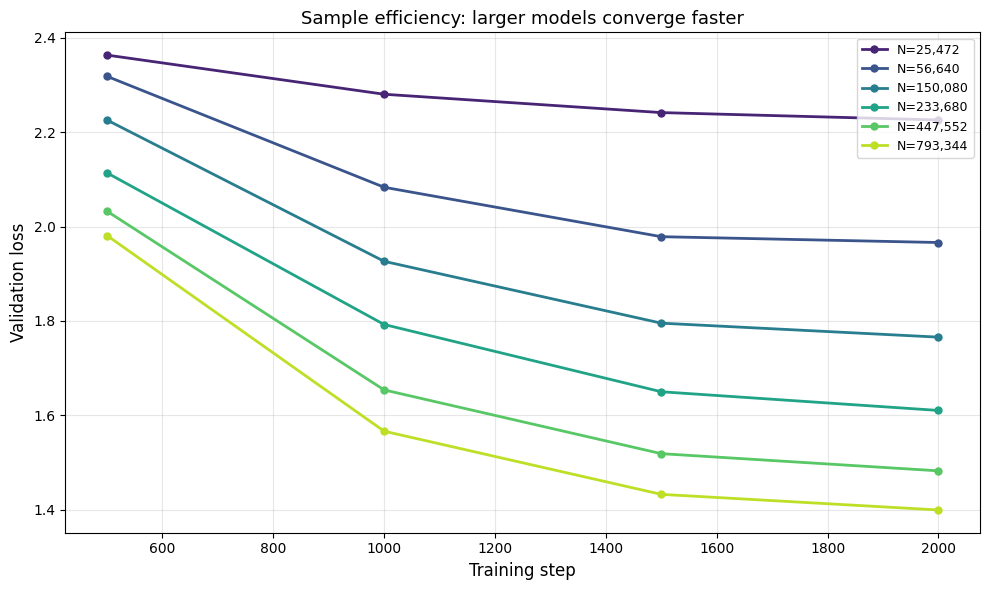

In [14]:
fig, ax = plt.subplots(1, 1, figsize=(10, 6))
colors = plt.cm.viridis(np.linspace(0.1, 0.9, len(results_N)))
for (n, vloss, vhist), color in zip(results_N, colors):
    steps_arr = [h[0] for h in vhist]
    vals_arr = [h[1] for h in vhist]
    ax.plot(steps_arr, vals_arr, '-o', color=color, markersize=5, linewidth=2, label=f'N={n:,}')

ax.set_xlabel('Training step', fontsize=12)
ax.set_ylabel('Validation loss', fontsize=12)
ax.set_title('Sample efficiency: larger models converge faster', fontsize=13)
ax.legend(fontsize=9, loc='upper right')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Summary

### What the run above shows

We trained 6 decoder-only Transformers (non-embedding parameters from 25,472 to 793,344) on
character-level WikiText-2 and fitted the power law $L(N) = (N_c/N)^{\alpha_N}$.
The fit produces a clean power law with R² = 0.9944, confirming the paper's central claim
that loss scales as a power of model size — even for models many orders of magnitude smaller
than the paper's 768-to-1.5B range. The fitted exponent $\alpha_N$ = 0.1367 is larger than
the paper's 0.076 because character-level modelling on a tiny corpus is a different (and steeper) regime.
Validation loss drops from 2.23 (25K params, perplexity 9.26) to 1.40 (793K params, perplexity 4.05).

The $L(N,D)$ experiment shows the overfitting effect: the largest model (793K params) overfits
severely on small data (val loss 8.87 at D=20K chars, with train loss 0.07 — classic memorisation),
while the smallest model (25K params) is barely affected. As data grows, the gap reverses: with the
full dataset the large model's loss (1.44) is well below the small model's (2.22), matching the paper's
Equation (1.5) prediction that overfitting depends on $N^{\alpha_N/\alpha_D}/D$.

The compute scaling $L(C)$ also follows a power law ($\alpha_C$ = 0.1367, R² = 0.9944), and the
training curves show that larger models reach lower validation loss in fewer steps, reproducing
the sample-efficiency observation from Figure 2.

These results are qualitative reproductions; absolute values of $\alpha_N$, $N_c$, etc. are
not comparable to the paper because our models are ~$10^6{\times}$ smaller and trained on
~$10^3{\times}$ less data with a different tokenisation.